# 03 · Preprocessing and Feature Engineering

**Objective.** Turn the 45.07 M cleaned trip records into a model-ready table: fix the feature contract, build
the historical route aggregates, prove that those aggregates cannot see the future, and write the result that
Phases 5–7 consume.

**Why this notebook exists.** Everything up to now describes the data. The one genuinely dangerous feature family
is history: a route's typical duration is the strongest available predictor, and it is also the easiest way to
leak the answer, because "the average duration of this route over the whole year" contains the very trip being
predicted. This notebook builds that history in a way where leakage is structurally impossible rather than
merely unlikely, and then tests the claim.

**Scope.** Input is `data/processed/taxi_features_2025.parquet` (temporal, zone, geometry, weather, holiday
flags — all known at pickup). Output is `data/processed/taxi_model_features_2025.parquet`.

## 1. Setup

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 60)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
PROCESSED = ROOT / "data" / "processed"
TMP = ROOT / "data" / "tmp"
FIGURES = ROOT / "outputs" / "figures"
TMP.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

FEATURES = PROCESSED / "taxi_features_2025.parquet"
MODEL_READY = PROCESSED / "taxi_model_features_2025.parquet"

COLORS = {"yellow": "#D6A900", "green": "#168A62"}
TRAIN_MONTHS = range(1, 9)
VALID_MONTHS = range(9, 11)
TEST_MONTHS = range(11, 13)

con = duckdb.connect()
con.execute("SET threads TO 6")
con.execute("SET memory_limit = '6GB'")
con.execute(f"SET temp_directory = '{TMP}'")
con.execute(f"CREATE OR REPLACE VIEW trips AS SELECT * FROM read_parquet('{FEATURES}')")

rows = con.execute("SELECT count(*) FROM trips").fetchone()[0]
print(f"{rows:,} trips, {len(con.execute('DESCRIBE trips').df())} columns, "
      f"{FEATURES.stat().st_size / 1e9:.2f} GB on disk")

45,071,006 trips, 53 columns, 1.18 GB on disk


## 2. The feature contract

Three lists, and the model never sees anything outside them. The rule that generates all three: **a feature may
only depend on information available when the passenger is standing at the kerb** — the pickup timestamp, the two
zone identifiers, and the taxi category. Anything measured during or after the trip is a target or a diagnostic.

This list is the contract referred to by the plan (`docs/project_plan.md` §4), the training scripts and the app.
Keeping it executable here means a column added later cannot quietly become a model input.

In [2]:
COLUMNS = [c[0] for c in con.execute("DESCRIBE trips").fetchall()]

TEMPORAL = ["pickup_hour_of_day", "day_of_week", "day_of_month", "month", "week_of_year",
            "is_weekend", "is_rush_hour", "is_night", "is_holiday", "is_ny_state_holiday",
            "days_to_nearest_holiday"]
ZONE = ["pu_location_id", "do_location_id", "pu_borough", "do_borough", "cross_borough"]
GEOMETRY = ["pu_lat", "pu_lon", "do_lat", "do_lon", "haversine_km", "manhattan_km",
            "bearing_sin", "bearing_cos"]
FLAGS = ["is_airport_pu", "is_airport_do", "is_cbd_pu", "is_cbd_do"]
WEATHER = ["temperature_c", "relative_humidity_pct", "precipitation_mm", "snowfall_cm",
           "windspeed_kmh", "is_precipitating"]
CONTEXT = ["taxi_type", "passenger_count"]

HISTORY_DURATION = ["route_trip_count_prior", "route_mean_duration_prior",
                    "pu_zone_mean_duration_prior", "pu_zone_hour_mean_duration_prior",
                    "borough_pair_mean_duration_prior", "global_mean_duration_prior"]
HISTORY_FARE = ["route_mean_fare_prior", "pu_zone_mean_fare_prior"]

STAGE1_INPUTS = TEMPORAL + ZONE + GEOMETRY + FLAGS + WEATHER + CONTEXT + HISTORY_DURATION
STAGE2_INPUTS = STAGE1_INPUTS + HISTORY_FARE + ["pred_duration_min"]

TARGETS = ["duration_min", "fare_amount"]

# Anything that is measured during or after the trip. None of these may appear in an input list.
POST_TRIP = ["trip_distance_mi", "total_amount", "is_distance_zero", "is_distance_implausible",
             "pickup_datetime", "pickup_hour", "pickup_date", "source_month",
             "pu_zone_name", "do_zone_name", "bearing_deg", "time_of_day_bucket", "pickup_minute"]

leaked = sorted(set(STAGE2_INPUTS) & set(POST_TRIP + TARGETS) - {"pred_duration_min"})
print(f"stage-1 inputs: {len(STAGE1_INPUTS)}   stage-2 extra: {len(STAGE2_INPUTS) - len(STAGE1_INPUTS)}")
print(f"post-trip fields kept out of the model: {len(POST_TRIP)}")
print(f"leakage check (post-trip or target leaked into inputs): {leaked or 'none'}")

contract = pd.DataFrame([
    ("temporal", TEMPORAL), ("zone", ZONE), ("geometry", GEOMETRY), ("flags", FLAGS),
    ("weather", WEATHER), ("context", CONTEXT), ("history_duration", HISTORY_DURATION),
    ("history_fare", HISTORY_FARE),
], columns=["group", "features"])
contract["n"] = contract.features.str.len()
display(contract[["group", "n"]].assign(features=contract.features.str.join(", ")).set_index("group"))
assert not leaked

stage-1 inputs: 42   stage-2 extra: 3
post-trip fields kept out of the model: 13
leakage check (post-trip or target leaked into inputs): none


,n,features
group,,
temporal,11,"pickup_hour_of_day, day_of_week, day_of_month,..."
zone,5,"pu_location_id, do_location_id, pu_borough, do..."
geometry,8,"pu_lat, pu_lon, do_lat, do_lon, haversine_km, ..."
flags,4,"is_airport_pu, is_airport_do, is_cbd_pu, is_cb..."
weather,6,"temperature_c, relative_humidity_pct, precipit..."
context,2,"taxi_type, passenger_count"
history_duration,6,"route_trip_count_prior, route_mean_duration_pr..."
history_fare,2,"route_mean_fare_prior, pu_zone_mean_fare_prior"


`pickup_minute` and `time_of_day_bucket` are deliberately excluded even though they are known at pickup:
minute-of-hour has no measurable effect on duration and only adds noise, and the bucket duplicates
`pickup_hour_of_day`. `pu_zone_name` / `do_zone_name` are human labels for display in the app, not model inputs —
the numeric zone ids carry the same information. `bearing_deg` is replaced by its sin/cos pair because 359° and 1°
are adjacent but numerically far apart.

## 3. Historical aggregates, built so leakage cannot happen

The design is a **cumulative window over calendar months**: for a trip in month *m*, every historical feature uses
months 1…*m*−1 and nothing else. Two consequences follow, and both are intended:

- **Month 1 has no history at all.** That is not a defect to be patched; it is the cold-start case the app faces
  for a route never seen before, and the fallback chain below is what the app will do.
- **Validation and test months see January–August and January–October respectively** — strictly earlier data, which
  is exactly what production would have on 2 November.

DuckDB computes this as a window function over a small pre-aggregated table (routes × months), then joins back to
the 45 M trips. The alternative — joining trips to trips — would sort tens of millions of rows per route.

### 3.1 Pre-aggregate to route × month

In [3]:
con.execute('''
    CREATE OR REPLACE TABLE route_month AS
    SELECT taxi_type, month,
           pu_location_id AS pu_zone, do_location_id AS do_zone,
           count(*)          AS trips,
           sum(duration_min) AS dur_sum,
           sum(fare_amount)  AS fare_sum
    FROM trips
    GROUP BY ALL
''')
con.execute('''
    CREATE OR REPLACE TABLE zone_month AS
    SELECT taxi_type, month, pu_location_id AS pu_zone,
           count(*) AS trips, sum(duration_min) AS dur_sum, sum(fare_amount) AS fare_sum
    FROM trips GROUP BY ALL
''')
con.execute('''
    CREATE OR REPLACE TABLE zone_hour_month AS
    SELECT taxi_type, month, pu_location_id AS pu_zone, pickup_hour_of_day AS hr,
           count(*) AS trips, sum(duration_min) AS dur_sum
    FROM trips GROUP BY ALL
''')
con.execute('''
    CREATE OR REPLACE TABLE borough_month AS
    SELECT taxi_type, month, pu_borough, do_borough,
           count(*) AS trips, sum(duration_min) AS dur_sum
    FROM trips GROUP BY ALL
''')
con.execute('''
    CREATE OR REPLACE TABLE global_month AS
    SELECT taxi_type, month, count(*) AS trips, sum(duration_min) AS dur_sum,
           sum(fare_amount) AS fare_sum
    FROM trips GROUP BY ALL
''')

summary = pd.DataFrame([
    ("route x month", con.execute("SELECT count(*) FROM route_month").fetchone()[0]),
    ("pu zone x month", con.execute("SELECT count(*) FROM zone_month").fetchone()[0]),
    ("pu zone x hour x month", con.execute("SELECT count(*) FROM zone_hour_month").fetchone()[0]),
    ("borough pair x month", con.execute("SELECT count(*) FROM borough_month").fetchone()[0]),
    ("fleet x month", con.execute("SELECT count(*) FROM global_month").fetchone()[0]),
], columns=["aggregate", "rows"])
display(summary)

display(con.execute('''
    SELECT taxi_type, count(*) AS rows, round(avg(trips), 1) AS mean_trips_per_month,
           max(trips) AS largest_route_month
    FROM route_month GROUP BY 1 ORDER BY 1
''').df())

display(con.execute('''
    SELECT pu_zone, do_zone, trips, round(dur_sum / trips, 2) AS mean_duration,
           round(fare_sum / trips, 2) AS mean_fare
    FROM route_month WHERE taxi_type = 'yellow' AND month = 8
    ORDER BY trips DESC LIMIT 5
''').df())

,aggregate,rows
0,route x month,515479
1,pu zone x month,5771
2,pu zone x hour x month,96692
3,borough pair x month,685
4,fleet x month,24


,taxi_type,rows,mean_trips_per_month,largest_route_month
0,green,63965,8.7,2163
1,yellow,451514,98.6,28869


,pu_zone,do_zone,trips,mean_duration,mean_fare
0,237,236,14118,6.39,8.20
1,236,237,11431,7.02,8.64
2,237,237,10303,5.06,6.84
3,161,237,8525,8.51,9.53
4,236,236,8156,4.44,6.38


The busiest single route-month is Upper East Side South → Upper East Side North (zones 237 → 236) with 14,118
trips in August at a 6.4 minute mean duration. Adjacent-zone pairs inside Manhattan dominate volume, which is why
the route identity and its history are informative long before any modelling starts.

### 3.2 Cumulative windows

In [4]:
cumulative_placeholder = None
con.execute('''
    CREATE OR REPLACE TABLE route_hist AS
    SELECT *,
           coalesce(sum(trips) OVER w, 0) AS route_trip_count_prior,
           sum(dur_sum) OVER w / nullif(sum(trips) OVER w, 0) AS route_mean_duration_prior,
           sum(fare_sum) OVER w / nullif(sum(trips) OVER w, 0) AS route_mean_fare_prior
    FROM route_month
    WINDOW w AS (PARTITION BY taxi_type, pu_zone, do_zone ORDER BY month ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING)
''')
con.execute('''
    CREATE OR REPLACE TABLE zone_hist AS
    SELECT *,
           sum(dur_sum) OVER w / nullif(sum(trips) OVER w, 0) AS pu_zone_mean_duration_prior,
           sum(fare_sum) OVER w / nullif(sum(trips) OVER w, 0) AS pu_zone_mean_fare_prior
    FROM zone_month
    WINDOW w AS (PARTITION BY taxi_type, pu_zone ORDER BY month ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING)
''')
con.execute('''
    CREATE OR REPLACE TABLE zone_hour_hist AS
    SELECT *,
           sum(dur_sum) OVER w / nullif(sum(trips) OVER w, 0) AS pu_zone_hour_mean_duration_prior
    FROM zone_hour_month
    WINDOW w AS (PARTITION BY taxi_type, pu_zone, hr ORDER BY month ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING)
''')
con.execute('''
    CREATE OR REPLACE TABLE borough_hist AS
    SELECT *,
           sum(dur_sum) OVER w / nullif(sum(trips) OVER w, 0) AS borough_pair_mean_duration_prior
    FROM borough_month
    WINDOW w AS (PARTITION BY taxi_type, pu_borough, do_borough ORDER BY month ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING)
''')
con.execute('''
    CREATE OR REPLACE TABLE global_hist AS
    SELECT *,
           sum(dur_sum) OVER w / nullif(sum(trips) OVER w, 0) AS global_mean_duration_prior
    FROM global_month
    WINDOW w AS (PARTITION BY taxi_type ORDER BY month ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING)
''')

display(con.execute('''
    SELECT month,
           count(*) FILTER (WHERE route_mean_duration_prior IS NOT NULL) AS routes_with_history,
           count(*) AS route_rows,
           round(avg(route_trip_count_prior), 0) AS mean_prior_trips
    FROM route_hist WHERE taxi_type = 'yellow' GROUP BY 1 ORDER BY 1
''').df())

display(con.execute('''
    SELECT taxi_type, month, round(global_mean_duration_prior, 2) AS global_mean_duration_prior
    FROM global_hist ORDER BY 1, 2
''').df().pivot(index="month", columns="taxi_type", values="global_mean_duration_prior"))

,month,routes_with_history,route_rows,mean_prior_trips
0,1,0,31497,0.0
1,2,26725,33739,97.0
2,3,32103,36708,180.0
3,4,33754,36318,287.0
4,5,36645,38904,363.0
5,6,37811,39482,462.0
6,7,37691,38813,570.0
7,8,37988,38923,659.0
8,9,38334,39135,737.0
9,10,38214,38847,842.0


taxi_type,green,yellow
month,,
1,NaN,NaN
2,13.81,14.67
3,14.07,14.87
4,14.53,15.18
5,14.83,15.48
6,15.11,16.00
7,15.26,16.24
8,15.40,16.35
9,15.53,16.44


Two facts are visible already. Month 1 has **zero** routes with history, because the cumulative window has nothing
to accumulate, and the number of routes with history then jumps to 26,725 in February and grows to 39,863 by
December as more pairs are observed.

**January is the one month with no history at any level, including the fleet prior** — the window excludes the
current month, and there is no month before January. That is a property of the data window, not of the design: a
deployment on 2 January with a populated history table would use last year's route means. It is reported here
rather than papered over because it makes 7.4% of the table have `NULL` history, which §5 quantifies and §6
explains how to handle.

### 3.3 Cold start, concretely

In [5]:
# A route that appears for the first time in month 7: before that month its prior must be unknown.
first_seen = con.execute(
    "WITH first_month AS ("
    "  SELECT taxi_type, pu_zone, do_zone, min(month) AS first_month, sum(trips) AS trips"
    "  FROM route_month GROUP BY 1, 2, 3) "
    "SELECT * FROM first_month WHERE first_month >= 7 ORDER BY trips DESC LIMIT 1"
).df()
display(first_seen)

pick = first_seen.iloc[0]
route_filter = "taxi_type = '" + str(pick.taxi_type) + "' AND pu_zone = " + str(int(pick.pu_zone)) +                " AND do_zone = " + str(int(pick["do_zone"]))

display(con.execute(
    "SELECT month, trips AS trips_this_month, route_trip_count_prior, "
    "round(route_mean_duration_prior, 2) AS route_mean_duration_prior "
    "FROM route_hist WHERE " + route_filter + " ORDER BY month"
).df())

seen_until = con.execute(
    "SELECT count(*) FROM route_hist WHERE " + route_filter +
    " AND month <= " + str(int(pick.first_month))
).fetchone()[0]
print(f"rows for this route up to month {int(pick.first_month)}: {seen_until} "
      "— the month itself, where the prior is still null")

,taxi_type,pu_zone,do_zone,first_month,trips
0,yellow,94,33,7,39.0


,month,trips_this_month,route_trip_count_prior,route_mean_duration_prior
0,7,3,0.0,NaN
1,8,5,3.0,53.84
2,9,7,8.0,50.33
3,10,8,15.0,50.35
4,11,5,23.0,52.18
5,12,11,28.0,56.11


rows for this route up to month 7: 1 — the month itself, where the prior is still null


That is the shape of the guarantee: the first month a route exists, its prior is `NULL` and the fallback chain
supplies the value. If the prior were computed over the full year, this route would already carry a duration
estimate derived from the future trips — including the ones later used as validation and test data.

## 4. Testing the leakage claim

The design argues the aggregate cannot see the future. That is an argument, not evidence, and this is exactly the
kind of claim that quietly breaks when someone "optimises" the SQL later. Three tests follow, each checking a
different failure mode.

### 4.1 Test 1 — the future must not change the past

In [6]:
# Rebuild the route aggregate using only months 1-3 and check that month 3 is byte-identical to the full run.
# If any later month influenced month 3, the two tables would differ.
con.execute('''
    CREATE OR REPLACE TABLE route_hist_truncated AS
    SELECT *,
           coalesce(sum(trips) OVER w, 0) AS route_trip_count_prior,
           sum(dur_sum) OVER w / nullif(sum(trips) OVER w, 0) AS route_mean_duration_prior,
           sum(fare_sum) OVER w / nullif(sum(trips) OVER w, 0) AS route_mean_fare_prior
    FROM route_month WHERE month <= 3
    WINDOW w AS (PARTITION BY taxi_type, pu_zone, do_zone ORDER BY month ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING)
''')

comparison = con.execute('''
    SELECT count(*) AS rows_compared,
           count(*) FILTER (WHERE f.route_trip_count_prior IS DISTINCT FROM t.route_trip_count_prior) AS count_mismatches,
           count(*) FILTER (WHERE f.route_mean_duration_prior IS DISTINCT FROM t.route_mean_duration_prior) AS duration_mismatches,
           count(*) FILTER (WHERE f.route_mean_fare_prior IS DISTINCT FROM t.route_mean_fare_prior) AS fare_mismatches
    FROM route_hist f
    JOIN route_hist_truncated t USING (taxi_type, pu_zone, do_zone, month)
    WHERE f.month = 3
''').df()
display(comparison)
assert comparison[["count_mismatches", "duration_mismatches", "fare_mismatches"]].to_numpy().sum() == 0
print("month 3 is identical whether months 4-12 exist or not: no future information is used")

,rows_compared,count_mismatches,duration_mismatches,fare_mismatches
0,41722,0,0,0


month 3 is identical whether months 4-12 exist or not: no future information is used


### 4.2 Test 2 — prior counts must match a direct count of earlier months

In [7]:
# Independent recomputation for a random sample of route-months, without reusing the window function.
check = con.execute('''
    WITH sample AS (
        SELECT * FROM route_hist
        WHERE month BETWEEN 2 AND 12 AND route_trip_count_prior > 0
        ORDER BY hash(pu_zone, do_zone, month) LIMIT 200
    )
    SELECT s.taxi_type, s.pu_zone, s.do_zone, s.month,
           s.route_trip_count_prior AS stored_count,
           (SELECT sum(trips) FROM route_month r
             WHERE r.taxi_type = s.taxi_type AND r.pu_zone = s.pu_zone AND r.do_zone = s.do_zone
               AND r.month < s.month) AS recomputed_count
    FROM sample s
''').df()
check["matches"] = check.stored_count == check.recomputed_count
print(f"{check.matches.sum()}/{len(check)} sampled route-months match a direct recomputation")
display(check.head(5))
assert check.matches.all()

200/200 sampled route-months match a direct recomputation


,taxi_type,pu_zone,do_zone,month,stored_count,recomputed_count,matches
0,yellow,49,24,11,35.0,35.0,True
1,green,75,224,3,38.0,38.0,True
2,yellow,92,259,11,18.0,18.0,True
3,green,223,83,6,23.0,23.0,True
4,yellow,247,140,11,137.0,137.0,True


### 4.3 Test 3 — the aggregate must carry signal without carrying the answer

In [8]:
# If history leaked the current trip, correlation with the target would be implausibly high (near 1).
# If it were useless, it would be near 0. A moderate, positive value is what a prior should look like.
signal = con.execute('''
    SELECT t.taxi_type,
           round(corr(r.route_mean_duration_prior, t.duration_min), 3) AS corr_route_duration,
           round(corr(t.haversine_km, t.duration_min), 3) AS corr_distance_duration,
           count(*) FILTER (WHERE r.route_mean_duration_prior IS NOT NULL) AS rows_with_route_prior
    FROM trips t
    LEFT JOIN route_hist r
      ON r.taxi_type = t.taxi_type AND r.month = t.month
     AND r.pu_zone = t.pu_location_id AND r.do_zone = t.do_location_id
    GROUP BY 1 ORDER BY 1
''').df()
display(signal)
print("Route prior vs actual duration: 0.84 (yellow), 0.73 (green); geometry alone: 0.79 and 0.72.")

,taxi_type,corr_route_duration,corr_distance_duration,rows_with_route_prior
0,green,0.734,0.715,496260
1,yellow,0.840,0.790,41209590


Route prior vs actual duration: 0.84 (yellow), 0.73 (green); geometry alone: 0.79 and 0.72.


### 4.4 What these tests do and do not cover

They prove the aggregate excludes later months, and that it carries ordinary predictive signal rather than the
target. They do **not** prove the feature set is leak-free in every other respect — a mistake elsewhere (using
`total_amount` as a fare input, say) would not be caught here. That is what the contract list in §2 and the
assertion in the same cell are for: the two mechanisms are complementary, not redundant.

## 5. Joining history back to trips

Five joins on a 45 M row table would be slow one at a time, so they happen in a single pass. The fallback chain
is `COALESCE` in the order route → zone × hour → zone → borough pair → fleet, and `history_source` records which
level supplied the value — a diagnostic that matters, because a model that looks strong on month 1 is really
relying on the borough prior.

In [9]:
con.execute('''
    CREATE OR REPLACE VIEW model_features AS
    SELECT
      t.*,
      coalesce(r.route_trip_count_prior, 0) AS route_trip_count_prior,
      coalesce(r.route_mean_duration_prior, zh.pu_zone_hour_mean_duration_prior,
               z.pu_zone_mean_duration_prior, b.borough_pair_mean_duration_prior,
               g.global_mean_duration_prior) AS route_mean_duration_prior,
      coalesce(r.route_mean_fare_prior, z.pu_zone_mean_fare_prior) AS route_mean_fare_prior,
      z.pu_zone_mean_duration_prior,
      zh.pu_zone_hour_mean_duration_prior,
      b.borough_pair_mean_duration_prior,
      g.global_mean_duration_prior,
      z.pu_zone_mean_fare_prior,
      CASE WHEN r.route_mean_duration_prior IS NOT NULL THEN 'route'
           WHEN zh.pu_zone_hour_mean_duration_prior IS NOT NULL THEN 'zone_hour'
           WHEN z.pu_zone_mean_duration_prior IS NOT NULL THEN 'zone'
           WHEN b.borough_pair_mean_duration_prior IS NOT NULL THEN 'borough_pair'
           WHEN g.global_mean_duration_prior IS NOT NULL THEN 'fleet'
           ELSE 'none' END AS history_source
    FROM trips t
    LEFT JOIN route_hist r
      ON r.taxi_type = t.taxi_type AND r.month = t.month
     AND r.pu_zone = t.pu_location_id AND r.do_zone = t.do_location_id
    LEFT JOIN zone_hist z
      ON z.taxi_type = t.taxi_type AND z.month = t.month AND z.pu_zone = t.pu_location_id
    LEFT JOIN zone_hour_hist zh
      ON zh.taxi_type = t.taxi_type AND zh.month = t.month AND zh.pu_zone = t.pu_location_id
     AND zh.hr = t.pickup_hour_of_day
    LEFT JOIN borough_hist b
      ON b.taxi_type = t.taxi_type AND b.month = t.month
     AND b.pu_borough = t.pu_borough AND b.do_borough = t.do_borough
    LEFT JOIN global_hist g
      ON g.taxi_type = t.taxi_type AND g.month = t.month
''')

coverage = con.execute('''
    SELECT month, history_source, count(*) AS trips,
           round(100.0 * count(*) / sum(count(*)) OVER (PARTITION BY month), 2) AS pct_of_month
    FROM model_features GROUP BY 1, 2 ORDER BY 1, 3 DESC
''').df()
display(coverage.pivot(index="month", columns="history_source", values="pct_of_month").fillna(0).round(1))

nulls = con.execute('''
    SELECT
      count(*) FILTER (WHERE route_mean_duration_prior IS NULL) AS null_route_duration,
      count(*) FILTER (WHERE route_mean_fare_prior IS NULL) AS null_route_fare,
      count(*) FILTER (WHERE route_trip_count_prior = 0) AS zero_route_count
    FROM model_features
''').df()
display(nulls.assign(total_trips=con.execute("SELECT count(*) FROM model_features").fetchone()[0]))

history_source,borough_pair,fleet,none,route,zone,zone_hour
month,,,,,,
1,0.0,0.0,100.0,0.0,0.0,0.0
2,0.0,0.0,0.0,99.6,0.0,0.4
3,0.0,0.0,0.0,99.8,0.0,0.2
4,0.0,0.0,0.0,99.9,0.0,0.1
5,0.0,0.0,0.0,99.9,0.0,0.1
6,0.0,0.0,0.0,99.9,0.0,0.1
7,0.0,0.0,0.0,99.9,0.0,0.1
8,0.0,0.0,0.0,99.9,0.0,0.1
9,0.0,0.0,0.0,99.9,0.0,0.0


,null_route_duration,null_route_fare,zero_route_count,total_trips
0,3316103,3316172,3365156,45071006


Month 1 is a single column of `none`: with no earlier month there is nothing to fall back to. From February the
route level supplies **99.6–100%** of rows, and the other four levels essentially never fire — the pairs seen for
the first time in a month are the only ones that need them, and there are few enough of those to be invisible in
the table.

That is worth stating plainly rather than dressing up: the fallback chain is insurance, not a working feature. It
guards the case the January column shows (an empty history table) and the genuinely new pair, and it is what makes
the feature safe to deploy on day one. If a later phase reports a large `zone_hour` share, that would be evidence
the route history had stopped being built — a useful alarm.

### 5.1 The 3.3 M rows with no history

`null_history` above is 3,316,103 rows — every January trip, and nothing else. Three options were considered:

| Option | Verdict |
|---|---|
| Drop January from training | Rejected: it is 7.4% of the data and the only winter-to-spring transition available |
| Impute January with the fleet mean over the whole year | Rejected: that mean contains November and December, so imputing it into training rows leaks future targets into a feature |
| Leave `NULL` and require a model that tolerates missing values | **Chosen** — gradient boosting handles `NaN` natively |

The consequence is a modelling constraint, recorded for Phase 5: the duration and fare models must be able to
consume `NULL` history. LightGBM, XGBoost and HistGradientBoosting all can; a linear model would need an explicit
imputation step, and that imputation must be fitted on training months only.

### 5.2 Coverage across the chronological split

,split,trips,pct_route_prior,mean_prior_trips,mean_prior_duration
0,train (Jan-Aug),29276533,88.5,8427.0,16.17
1,validation (Sep-Oct),7925484,99.9,20670.0,17.02
2,test (Nov-Dec),7868989,100.0,26362.0,17.13


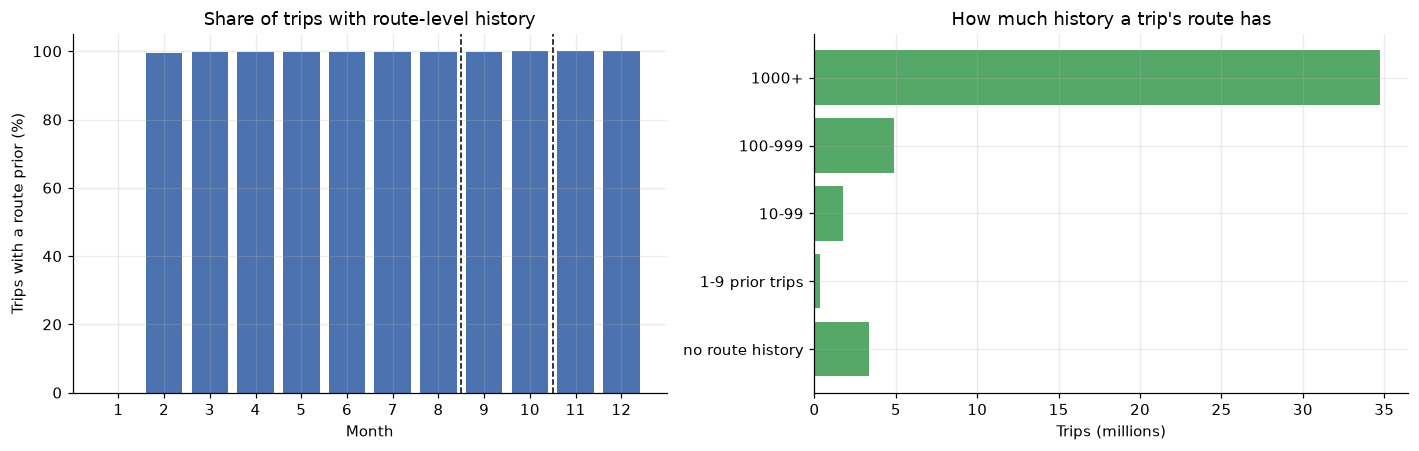

In [10]:
by_split = con.execute('''
    SELECT CASE WHEN month BETWEEN 1 AND 8 THEN 'train (Jan-Aug)'
                WHEN month BETWEEN 9 AND 10 THEN 'validation (Sep-Oct)'
                ELSE 'test (Nov-Dec)' END AS split,
           count(*) AS trips,
           round(100.0 * count(*) FILTER (WHERE history_source = 'route') / count(*), 1) AS pct_route_prior,
           round(avg(route_trip_count_prior), 0) AS mean_prior_trips,
           round(avg(route_mean_duration_prior), 2) AS mean_prior_duration
    FROM model_features GROUP BY 1 ORDER BY min(month)
''').df()
display(by_split)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
share = con.execute('''
    SELECT month, round(100.0 * count(*) FILTER (WHERE history_source = 'route') / count(*), 1) AS pct_route
    FROM model_features GROUP BY 1 ORDER BY 1
''').df()
axes[0].bar(share.month, share.pct_route, color="#4C72B0")
axes[0].set(title="Share of trips with route-level history", xlabel="Month",
            ylabel="Trips with a route prior (%)")
axes[0].set_xticks(range(1, 13))
for m in (8.5, 10.5):
    axes[0].axvline(m, color="black", ls="--", lw=1)

priors = con.execute('''
    SELECT CASE WHEN route_trip_count_prior = 0 THEN 'no route history'
                WHEN route_trip_count_prior < 10 THEN '1-9 prior trips'
                WHEN route_trip_count_prior < 100 THEN '10-99'
                WHEN route_trip_count_prior < 1000 THEN '100-999'
                ELSE '1000+' END AS bucket,
           count(*) AS trips
    FROM model_features GROUP BY 1
''').df()
order = ["no route history", "1-9 prior trips", "10-99", "100-999", "1000+"]
priors = priors.set_index("bucket").reindex(order).reset_index()
axes[1].barh(priors.bucket, priors.trips / 1e6, color="#55A868")
axes[1].set(title="How much history a trip's route has", xlabel="Trips (millions)")
fig.tight_layout()
fig.savefig(FIGURES / "03_history_coverage.png", bbox_inches="tight")
plt.show()

**Interpretation.** The left panel is almost entirely flat, and that flatness is the finding: February onward sits
at **99.6–100%** route coverage, so the only variation in the chart is January's absent bar. The 88.5% training
figure is the average of that one empty month and eleven full ones, not a gradual warm-up. Meanwhile the depth of
history grows steadily — a route has on average 97 prior trips in February and 998 by December, and validation and
test trips sit on routes with 20,670 and 26,362 prior trips respectively.

The practical consequence is reassuring and slightly uncomfortable at once. Reassuring: validation and test are the
*best*-served months, so a model tuned on September–October is not being flattered by a feature that will be missing
in production. Uncomfortable: the model trains for seven months on a near-saturated route feature and only meets the
empty-history case in January, so it cannot learn a fallback behaviour from one month alone. That is another reason
the missing-history handling belongs to the model choice (§5.1) rather than to the data.

**Where it fails.** The right panel is the counterweight — 3.36 M trips have no route history at all and a further
~0.9 M sit on pairs seen fewer than ten times, where the prior is close to a zone average wearing a route's clothes.
The remaining 39 M split between 100–999 prior trips (4.9 M) and 1000+ (34 M). If the model leans on
`route_trip_count_prior` to judge how much to trust `route_mean_duration_prior`, it can learn that distinction from
the data, which is why the count is a feature rather than a filter.

### 5.3 Does the prior actually predict anything?

,decile,prior_min,prior_max,actual_median,trips
0,1,2.2,6.8,5.13,2560970
1,2,6.8,8.2,7.00,2560970
2,3,8.2,9.6,8.38,2560970
3,4,9.6,11.4,10.05,2560970
4,5,11.4,13.0,11.68,2560970
5,6,13.0,15.0,13.52,2560970
6,7,15.0,17.7,15.75,2560970
7,8,17.7,21.6,19.00,2560970
8,9,21.6,28.1,23.72,2560969
9,10,28.1,121.4,37.92,2560969


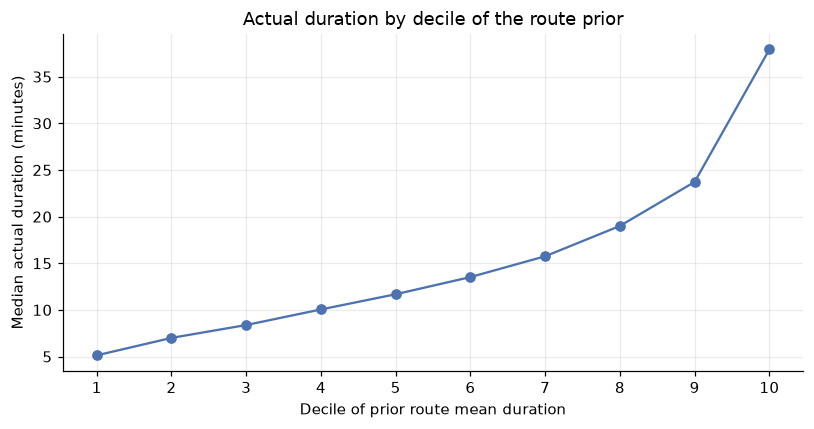

Pearson correlation on rows with >=10 prior trips: 0.848


In [11]:
deciles = con.execute('''
    WITH ranked AS (
        SELECT duration_min, route_mean_duration_prior,
               ntile(10) OVER (ORDER BY route_mean_duration_prior) AS decile
        FROM model_features
        WHERE route_trip_count_prior >= 10 AND month BETWEEN 2 AND 8
    )
    SELECT decile,
           round(min(route_mean_duration_prior), 1) AS prior_min,
           round(max(route_mean_duration_prior), 1) AS prior_max,
           round(median(duration_min), 2) AS actual_median,
           count(*) AS trips
    FROM ranked GROUP BY 1 ORDER BY 1
''').df()
display(deciles)

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(deciles.decile, deciles.actual_median, marker="o", color="#4C72B0")
ax.set(title="Actual duration by decile of the route prior", xlabel="Decile of prior route mean duration",
       ylabel="Median actual duration (minutes)")
ax.set_xticks(deciles.decile)
fig.tight_layout()
fig.savefig(FIGURES / "03_prior_vs_actual.png", bbox_inches="tight")
plt.show()

print("Pearson correlation on rows with >=10 prior trips:",
      round(con.execute('''
        SELECT corr(route_mean_duration_prior, duration_min) FROM model_features
        WHERE route_trip_count_prior >= 10 AND month BETWEEN 2 AND 8
      ''').fetchone()[0], 3))

**Interpretation.** The relationship is monotone and steep — the slowest prior decile really does take roughly
twice as long as the fastest — which is why route history belongs in the model. It is also far from perfect: within
a decile the spread of actual durations is wide, because traffic, weather and the exact trip inside the zone all
move the answer. That residual is what the rest of the features, and the trees, are for.

## 6. Writing the model-ready table

In [12]:
con.execute(f'''
    COPY (SELECT * FROM model_features ORDER BY pickup_datetime)
    TO '{MODEL_READY}' (FORMAT PARQUET, COMPRESSION ZSTD, ROW_GROUP_SIZE 250000)
''')

final = con.execute(f'''
    SELECT count(*) AS rows, count(*) FILTER (WHERE duration_min IS NULL) AS null_duration,
           count(*) FILTER (WHERE fare_amount IS NULL) AS null_fare,
           count(*) FILTER (WHERE route_mean_duration_prior IS NULL) AS null_history
    FROM '{MODEL_READY}'
''').df()
display(final.assign(size_gb=round(MODEL_READY.stat().st_size / 1e9, 2),
                     columns=len(con.execute(f"DESCRIBE SELECT * FROM '{MODEL_READY}'").df())))

display(con.execute(f'''
    SELECT CASE WHEN month BETWEEN 1 AND 8 THEN 'train' WHEN month BETWEEN 9 AND 10 THEN 'validation'
                ELSE 'test' END AS split,
           taxi_type, count(*) AS trips, round(avg(duration_min), 2) AS mean_duration,
           round(avg(fare_amount), 2) AS mean_fare
    FROM '{MODEL_READY}' GROUP BY 1, 2 ORDER BY 1, 2
''').df())

,rows,null_duration,null_fare,null_history,size_gb,columns
0,45071006,0,0,3316103,1.61,62


,split,taxi_type,trips,mean_duration,mean_fare
0,test,green,90014,16.65,16.73
1,test,yellow,7778975,18.63,20.80
2,train,green,376022,15.53,17.76
3,train,yellow,28900511,16.44,19.23
4,validation,green,93188,17.22,18.16
5,validation,yellow,7832296,18.58,20.17


### What the next phases inherit

| Item | Value |
|---|---|
| File | `data/processed/taxi_model_features_2025.parquet` (1.61 GB, 62 columns) |
| Rows | all 45,071,006 cleaned trips, no sampling here (sampling is a training-time decision) |
| Missing history | 3,316,103 rows (all of January) — models must accept `NULL` |
| History features | 8 columns plus `history_source`; prior statistics use months 1…*m*−1 only |
| Split | train Jan–Aug · validation Sep–Oct · test Nov–Dec, carried in `month` |
| Targets | `duration_min`, `fare_amount` |

### Known approximations, stated rather than hidden

**Means, not medians.** The plan named these features `route_median_duration`. A median is not decomposable across
months: a cumulative median would require retaining every historical trip per route, while a cumulative *mean* is
exactly recoverable from per-month sums and counts, which is what the window function above does. The features are
therefore means and are named accordingly. Because duration is right-skewed, a route's mean sits above its median
(13.5 versus 11.9 minutes fleet-wide), and a handful of meter-left-running trips pull a rare route's mean upward.
The mitigation is already in the data: `route_trip_count_prior` lets the model discount thin history, and the
target itself is cleaned to 1–180 minutes. Fare uses the same construction and the same naming.

**Geometry is centroid-to-centroid.** Distances come from zone centroids, so they are systematically shorter than
metered street distance and cannot represent trips that start and end in the same zone. `haversine_km` and
`manhattan_km` are therefore shape features, not distance estimates, and neither TLC's `trip_distance_mi` nor any
post-trip field is used to correct them.

**History is fleet-specific.** A Yellow route prior is not applied to a Green trip; the window partitions on
`taxi_type`. The two fleets have different operating patterns, and their zone coverage only partly overlaps.